In [1]:
import pandas as pd
import os
from datetime import date

FILE_NAME = "expenses.csv"
COLUMNS = ["Date", "Category", "Amount", "Description"]

print("Personal Expense Tracker")
print("Project initialized successfully!")

Personal Expense Tracker
Project initialized successfully!


In [2]:
if os.path.exists(FILE_NAME):
    expenses = pd.read_csv(FILE_NAME)
    expenses = expenses.reindex(columns=COLUMNS)
    print("Previous expense records loaded.")
else:
    expenses = pd.DataFrame(columns=COLUMNS)
    print("New expense tracker created.")

print("Total records:", len(expenses))
display(expenses)

Previous expense records loaded.
Total records: 1


,Date,Category,Amount,Description
0,2026-10-19,Food,500.0,NaN


In [3]:
def add_expense():
    global expenses

    expense_date = input(
        "Enter date (YYYY-MM-DD) or press Enter for today: "
    ).strip()

    if expense_date == "":
        expense_date = date.today().isoformat()

    try:
        expense_date = date.fromisoformat(
            expense_date
        ).isoformat()
    except ValueError:
        print("Invalid date. Please use YYYY-MM-DD.")
        return

    category = input(
        "Enter category (Food/Travel/Shopping/Bills/Other): "
    ).strip()

    if category == "":
        print("Category cannot be empty.")
        return

    try:
        amount = float(input("Enter expense amount: "))

        if amount <= 0:
            print("Amount must be greater than zero.")
            return

    except ValueError:
        print("Please enter a valid number.")
        return

    description = input("Enter description: ").strip()

    new_expense = pd.DataFrame([{
        "Date": expense_date,
        "Category": category.title(),
        "Amount": amount,
        "Description": description
    }])

    # Add the first record without concatenating an empty table
    if expenses.empty:
        expenses = new_expense.copy()
    else:
        expenses = pd.concat(
            [expenses, new_expense],
            ignore_index=True
        )

    expenses.to_csv(FILE_NAME, index=False)

    print("Expense added and saved successfully!")

In [4]:
def view_expenses():
    if expenses.empty:
        print("No expenses recorded yet.")
    else:
        print("Your Expense Records:")
        display(expenses)

In [5]:
def total_expenses():
    total = expenses["Amount"].sum()

    print(f"Total Expenses: ₹{total:.2f}")

    return total

In [6]:
def category_summary():
    if expenses.empty:
        print("No expenses available for summary.")
        return

    summary = expenses.groupby("Category")["Amount"].sum()

    print("Category-wise Expenses:")
    display(summary.to_frame(name="Total Amount"))

In [7]:
def check_budget():
    try:
        budget = float(input("Enter your budget in rupees: "))

        if budget < 0:
            print("Budget cannot be negative.")
            return

    except ValueError:
        print("Please enter a valid budget.")
        return

    total = expenses["Amount"].sum()
    remaining = budget - total

    print(f"Budget: ₹{budget:.2f}")
    print(f"Total Expenses: ₹{total:.2f}")

    if remaining > 0:
        print(f"Remaining Budget: ₹{remaining:.2f}")
    elif remaining == 0:
        print("You have used your entire budget.")
    else:
        print(f"Budget exceeded by ₹{-remaining:.2f}")

In [ ]:
while True:
    print("\n===== PERSONAL EXPENSE TRACKER =====")
    print("1. Add Expense")
    print("2. View All Expenses")
    print("3. Calculate Total Expenses")
    print("4. Category-wise Summary")
    print("5. Check Budget")
    print("6. Exit")

    choice = input("Enter your choice (1-6): ").strip()

    if choice == "1":
        add_expense()

    elif choice == "2":
        view_expenses()

    elif choice == "3":
        total_expenses()

    elif choice == "4":
        category_summary()

    elif choice == "5":
        check_budget()

    elif choice == "6":
        print("Thank you for using the Expense Tracker!")
        break

    else:
        print("Invalid choice. Please select 1 to 6.")


===== PERSONAL EXPENSE TRACKER =====
1. Add Expense
2. View All Expenses
3. Calculate Total Expenses
4. Category-wise Summary
5. Check Budget
6. Exit


Enter your choice (1-6):  1
Enter date (YYYY-MM-DD) or press Enter for today:  
Enter category (Food/Travel/Shopping/Bills/Other):  shopping
Enter expense amount:  4000
Enter description:  Clothes Shopping


Expense added and saved successfully!

===== PERSONAL EXPENSE TRACKER =====
1. Add Expense
2. View All Expenses
3. Calculate Total Expenses
4. Category-wise Summary
5. Check Budget
6. Exit


Enter your choice (1-6):  2


Your Expense Records:


...

Category-wise Expenses:


,Total Amount
Category,
Bills,3000.0
Food,500.0
Shopping,4000.0



===== PERSONAL EXPENSE TRACKER =====
1. Add Expense
2. View All Expenses
3. Calculate Total Expenses
4. Category-wise Summary
5. Check Budget
6. Exit


Enter your choice (1-6):  5
Enter your budget in rupees:  10000


Budget: ₹10000.00
Total Expenses: ₹7500.00
Remaining Budget: ₹2500.00

===== PERSONAL EXPENSE TRACKER =====
1. Add Expense
2. View All Expenses
3. Calculate Total Expenses
4. Category-wise Summary
5. Check Budget
6. Exit


In [9]:
print("CSV file exists:", os.path.exists(FILE_NAME))
display(pd.read_csv(FILE_NAME))

CSV file exists: True


,Date,Category,Amount,Description
0,2026-10-19,Food,500.0,NaN
1,2026-10-19,Bills,3000.0,This bill is used for furniture


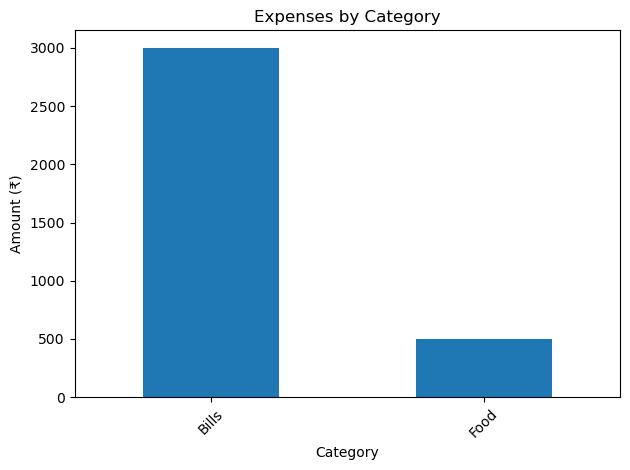

In [11]:
import matplotlib.pyplot as plt

def plot_expenses():
    if expenses.empty:
        print("No expenses available to plot.")
        return

    summary = expenses.groupby("Category")["Amount"].sum()

    summary.plot(kind="bar")
    plt.title("Expenses by Category")
    plt.xlabel("Category")
    plt.ylabel("Amount (₹)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

plot_expenses()